In [1]:

 # Cellule 0 - Setup + chargement dataset Flipkart (Colab + Google Drive)

import json
import zipfile
from pathlib import Path

import pandas as pd

# 0) (Optionnel) Monter Google Drive si ce n'est pas déjà fait
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

# 1) Chemins
ZIP_PATH = Path("/content/drive/MyDrive/Master AI Engineer/Colab Notebooks/Projet 6/Dataset+projet+prétraitement+textes+images.zip")
EXTRACT_DIR = Path("/content/data_flipkart")

# 2) Extraction (une seule fois)
if not EXTRACT_DIR.exists():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

# 3) Chargement du CSV
csv_path = EXTRACT_DIR / "Flipkart" / "flipkart_com-ecommerce_sample_1050.csv"
df = pd.read_csv(csv_path)

# 4) Création du label (catégorie niveau 1)
def get_label_lvl1(cat_tree_str: str) -> str:
    # cat_tree_str ressemble à: ["Home Furnishing >> Curtains & Accessories >> ..."]
    tree = json.loads(cat_tree_str)
    return tree[0].split(" >> ")[0].strip()

df["label_lvl1"] = df["product_category_tree"].apply(get_label_lvl1)

# 5) Vérifs rapides
images_dir = EXTRACT_DIR / "Flipkart" / "Images"
first_img_name = df.loc[0, "image"]
first_img_path = images_dir / first_img_name

print("Shape df:", df.shape)
print("\nRépartition label_lvl1:")
print(df["label_lvl1"].value_counts())

print("\nColonnes:", list(df.columns))
print("\nExemple image (ligne 0):", first_img_name)
print("Image existe ?", first_img_path.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape df: (1050, 16)

Répartition label_lvl1:
label_lvl1
Home Furnishing               150
Baby Care                     150
Watches                       150
Home Decor & Festive Needs    150
Kitchen & Dining              150
Beauty and Personal Care      150
Computers                     150
Name: count, dtype: int64

Colonnes: ['uniq_id', 'crawl_timestamp', 'product_url', 'product_name', 'product_category_tree', 'pid', 'retail_price', 'discounted_price', 'image', 'is_FK_Advantage_product', 'description', 'product_rating', 'overall_rating', 'brand', 'product_specifications', 'label_lvl1']

Exemple image (ligne 0): 55b85ea15a1536d46b7190ad6fff8ce7.jpg
Image existe ? True


In [2]:
# Cellule 1 - Contrôles qualité + aperçu des données utiles

# 1) Colonnes utiles pour le projet
cols_use = ["product_name", "description", "image", "product_category_tree", "label_lvl1"]
print("Colonnes utiles présentes :", [c for c in cols_use if c in df.columns])

# 2) Valeurs manquantes sur ces colonnes
missing = df[cols_use].isna().sum().sort_values(ascending=False)
print("\nValeurs manquantes (colonnes utiles) :")
print(missing)

# 3) Doublons éventuels
print("\nNombre de lignes dupliquées (toutes colonnes) :", df.duplicated().sum())
print("Nombre d'images dupliquées :", df["image"].duplicated().sum())

# 4) Longueur des descriptions (car ça impacte fortement les features texte)
desc = df["description"].fillna("").astype(str)
df["desc_len"] = desc.str.len()
print("\nStatistiques longueur description (en nb de caractères) :")
print(df["desc_len"].describe())

# 5) Exemples (pour vérifier le contenu)
sample = df.sample(3, random_state=42)[["label_lvl1", "product_name", "desc_len", "image"]]
print("\nExemples aléatoires :")
display(sample)

# 6) Vérifier rapidement le format de product_category_tree
print("\nExemple product_category_tree (ligne 0) :")
print(df.loc[0, "product_category_tree"])


Colonnes utiles présentes : ['product_name', 'description', 'image', 'product_category_tree', 'label_lvl1']

Valeurs manquantes (colonnes utiles) :
product_name             0
description              0
image                    0
product_category_tree    0
label_lvl1               0
dtype: int64

Nombre de lignes dupliquées (toutes colonnes) : 0
Nombre d'images dupliquées : 0

Statistiques longueur description (en nb de caractères) :
count    1050.000000
mean      473.820952
std       457.910422
min       109.000000
25%       192.000000
50%       278.000000
75%       588.250000
max      3490.000000
Name: desc_len, dtype: float64

Exemples aléatoires :


,label_lvl1,product_name,desc_len,image
352,Computers,Zyxel PLA-4205,141,833a87b0af3b84fe246d2ebf271af177.jpg
689,Kitchen & Dining,Philips 9.5 W LED B22 3000K A55 IND Bulb,211,55195de3873fffaa9e37b041533d7305.jpg
485,Computers,Lapguard Lenovo IdeaPad V470 6 Cell Laptop Bat...,1674,44b963eb856b4831dfdd21b666593c95.jpg



Exemple product_category_tree (ligne 0) :
["Home Furnishing >> Curtains & Accessories >> Curtains >> Elegance Polyester Multicolor Abstract Eyelet Do..."]


In [3]:
# Cellule 2 - Prétraitement texte simple

import re

def clean_text(s: str) -> str:
    s = str(s).lower()
    # Remplacer les retours à la ligne / tabulations par espace
    s = re.sub(r"[\r\n\t]+", " ", s)
    # Garder lettres + espaces (on enlève ponctuation et chiffres)
    s = re.sub(r"[^a-z\s]", " ", s)
    # Réduire les espaces multiples
    s = re.sub(r"\s+", " ", s).strip()
    return s

df["description_clean"] = df["description"].apply(clean_text)

# Contrôle: longueur avant/après
df["desc_clean_len"] = df["description_clean"].str.len()

print("Longueur description (brut) :")
print(df["desc_len"].describe())

print("\nLongueur description (clean) :")
print(df["desc_clean_len"].describe())

# Montrer 3 exemples avant/après
ex = df.sample(3, random_state=0)[["label_lvl1", "description", "description_clean"]]
display(ex)


Longueur description (brut) :
count    1050.000000
mean      473.820952
std       457.910422
min       109.000000
25%       192.000000
50%       278.000000
75%       588.250000
max      3490.000000
Name: desc_len, dtype: float64

Longueur description (clean) :
count    1050.000000
mean      435.297143
std       432.537688
min        69.000000
25%       170.000000
50%       248.000000
75%       536.750000
max      3368.000000
Name: desc_clean_len, dtype: float64


,label_lvl1,description,description_clean
743,Kitchen & Dining,Nutcase Sticker Wrap Design - Pineapple 800 ml...,nutcase sticker wrap design pineapple ml bottl...
656,Baby Care,Buy BornBabyKids Cotton Bath Towel at Rs. 589 ...,buy bornbabykids cotton bath towel at rs at fl...
704,Home Furnishing,"Buy Home Originals Abstract, Abstract Double B...",buy home originals abstract abstract double bl...


Matrice TF-IDF : (1050, 4979)
ARI (0=hasard, 1=parfait) : 0.284
NMI (0=hasard, 1=parfait) : 0.484


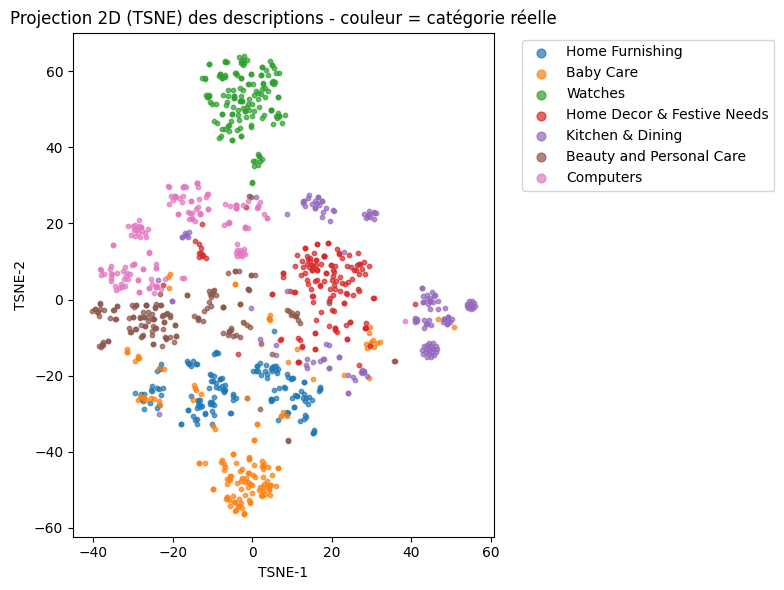

In [4]:
# Cellule 3 - Features texte (TF-IDF) + réduction 2D + clustering + métriques

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import matplotlib.pyplot as plt

# 1) Matrice TF-IDF
vectorizer = TfidfVectorizer(
    max_features=5000,   # limite pour rester raisonnable
    stop_words="english" # descriptions en anglais
)
X_tfidf = vectorizer.fit_transform(df["description_clean"])

print("Matrice TF-IDF :", X_tfidf.shape)

# 2) Clustering (on impose 7 clusters car on a 7 catégories)
n_clusters = df["label_lvl1"].nunique()
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_tfidf)

# 3) Métriques de comparaison clusters vs labels réels
y_true = df["label_lvl1"].astype("category").cat.codes

ari = adjusted_rand_score(y_true, clusters)
nmi = normalized_mutual_info_score(y_true, clusters)

print(f"ARI (0=hasard, 1=parfait) : {ari:.3f}")
print(f"NMI (0=hasard, 1=parfait) : {nmi:.3f}")

# 4) Réduction 2D pour visualisation (TSNE sur un sous-espace dense)
# TSNE accepte mal les matrices creuses -> on passe en dense après réduction simple
X_dense = X_tfidf.toarray()

tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca", learning_rate="auto")
X_2d = tsne.fit_transform(X_dense)

# 5) Scatter plot coloré par catégorie réelle
plt.figure(figsize=(8, 6))
for label in df["label_lvl1"].unique():
    mask = df["label_lvl1"] == label
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=10, alpha=0.7, label=label)

plt.title("Projection 2D (TSNE) des descriptions - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


TF-IDF (1050, 4979) : normal.

ARI = 0.284 : c’est un score “modéré”.
0 = hasard, 1 = parfait. 0.28 signifie que le clustering retrouve une partie de la structure des catégories, mais pas totalement.

NMI = 0.484 : plutôt correct pour un clustering non supervisé sur des descriptions hétérogènes.
En pratique, sur des données e-commerce, si le texte est informatif, on peut obtenir une séparation partielle, ce qui est exactement ce que montre le graph

In [5]:
# Cellule 3bis - Comparaison Count vs TF-IDF (mêmes métriques)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

y_true = df["label_lvl1"].astype("category").cat.codes
n_clusters = df["label_lvl1"].nunique()

def eval_vectorizer(vectorizer, texts, name: str):
    X = vectorizer.fit_transform(texts)
    km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cl = km.fit_predict(X)
    ari = adjusted_rand_score(y_true, cl)
    nmi = normalized_mutual_info_score(y_true, cl)
    print(f"{name} -> shape={X.shape} | ARI={ari:.3f} | NMI={nmi:.3f}")

# Paramètres simples pour limiter le bruit
count_vec = CountVectorizer(stop_words="english", max_features=5000, min_df=2, max_df=0.9)
tfidf_vec = TfidfVectorizer(stop_words="english", max_features=5000, min_df=2, max_df=0.9)

eval_vectorizer(count_vec, df["description_clean"], "CountVectorizer")
eval_vectorizer(tfidf_vec, df["description_clean"], "TfidfVectorizer")


CountVectorizer -> shape=(1050, 2235) | ARI=0.134 | NMI=0.301
TfidfVectorizer -> shape=(1050, 2235) | ARI=0.266 | NMI=0.520


TF-IDF fait mieux que Count sur ce dataset (ARI 0.266 vs 0.134, NMI 0.520 vs 0.301).

Donc pour la suite, on garde TF-IDF comme représentation texte principale

Taux d'images trouvées: 1.000


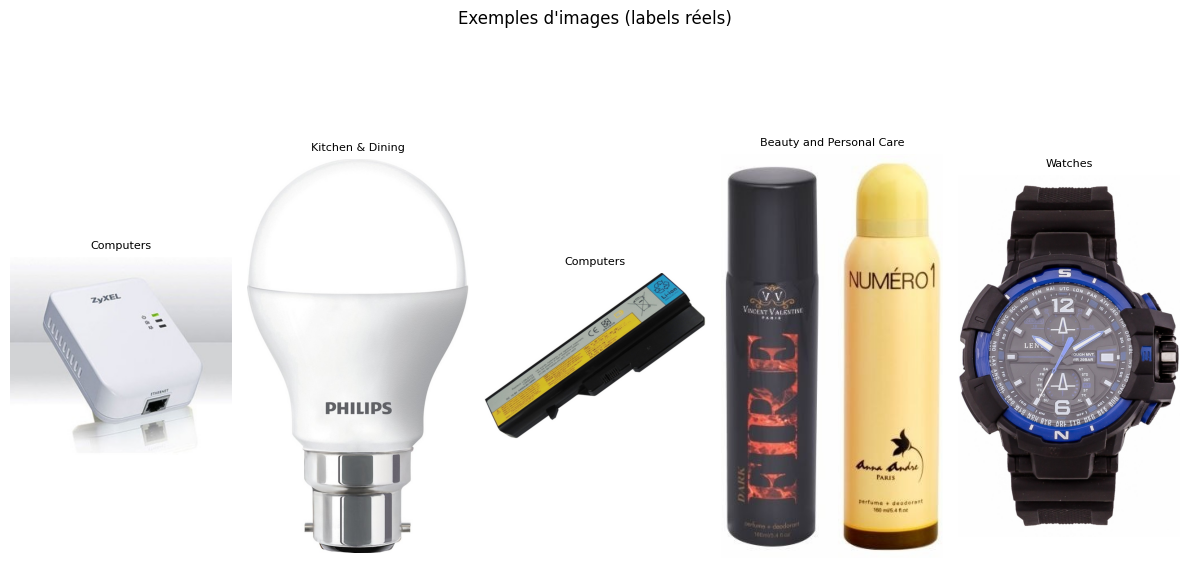


Tailles (width, height) des 5 exemples: [(400, 357), (776, 1380), (1966, 1475), (273, 497), (1257, 2049)]

Image prétraitée shape: (224, 224, 3) | min: 0.0 | max: 1.0


In [6]:
# Cellule 4 - Vérification et prétraitement image (chargement + resize)

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

images_dir = Path("/content/data_flipkart/Flipkart/Images")

# 1) Vérifier que toutes les images existent
exists_ratio = (df["image"].apply(lambda x: (images_dir / x).exists())).mean()
print(f"Taux d'images trouvées: {exists_ratio:.3f}")

# 2) Charger quelques images et afficher leurs tailles
sample_idx = df.sample(5, random_state=42).index.tolist()
sizes = []

plt.figure(figsize=(12, 6))
for i, idx in enumerate(sample_idx, 1):
    img_path = images_dir / df.loc[idx, "image"]
    img = Image.open(img_path).convert("RGB")
    sizes.append(img.size)  # (width, height)

    plt.subplot(1, 5, i)
    plt.imshow(img)
    plt.axis("off")
    plt.title(df.loc[idx, "label_lvl1"], fontsize=8)

plt.suptitle("Exemples d'images (labels réels)", y=1.05)
plt.tight_layout()
plt.show()

print("\nTailles (width, height) des 5 exemples:", sizes)

# 3) Fonction de prétraitement (resize + normalisation 0-1)
def preprocess_image(img_path: Path, target_size=(224, 224)) -> np.ndarray:
    img = Image.open(img_path).convert("RGB")
    img = img.resize(target_size)
    arr = np.array(img, dtype=np.float32) / 255.0
    return arr

# Test sur une image
test_path = images_dir / df.loc[0, "image"]
arr = preprocess_image(test_path)
print("\nImage prétraitée shape:", arr.shape, "| min:", arr.min(), "| max:", arr.max())


In [7]:
# Cellule 5 - Features images (CNN transfer learning) + clustering + métriques

import numpy as np
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1) Modèle pré-entraîné en extracteur de features
# include_top=False -> on enlève la couche de classification ImageNet
# pooling="avg" -> on récupère un vecteur (2048) par image
model = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))

# 2) Fonction de prétraitement adaptée à ResNet50
def preprocess_for_resnet(img_path: Path) -> np.ndarray:
    img = Image.open(img_path).convert("RGB")
    img = img.resize((224, 224))
    arr = img_to_array(img)  # float32
    arr = np.expand_dims(arr, axis=0)  # (1, 224, 224, 3)
    arr = preprocess_input(arr)        # normalisation spécifique ResNet
    return arr

# 3) Extraction des features (un vecteur par image)
features = []
paths = []

for img_name in tqdm(df["image"].tolist(), desc="Extraction features"):
    img_path = images_dir / img_name
    x = preprocess_for_resnet(img_path)
    feat = model.predict(x, verbose=0)  # (1, 2048)
    features.append(feat[0])
    paths.append(str(img_path))

X_img = np.array(features)
print("Features images shape:", X_img.shape)

# 4) Clustering + métriques
n_clusters = df["label_lvl1"].nunique()
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_img = kmeans.fit_predict(X_img)

y_true = df["label_lvl1"].astype("category").cat.codes
ari_img = adjusted_rand_score(y_true, clusters_img)
nmi_img = normalized_mutual_info_score(y_true, clusters_img)

print(f"ARI image : {ari_img:.3f}")
print(f"NMI image : {nmi_img:.3f}")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Extraction features:  64%|██████▍   | 677/1050 [04:19<02:06,  2.94it/s]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (93680328 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Extraction features: 100%|██████████| 1050/1050 [06:45<00:00,  2.59it/s]


Features images shape: (1050, 2048)
ARI image : 0.493
NMI image : 0.587


Après PCA: (1050, 50)
Variance expliquée cumulée (50 composantes): 0.61955625


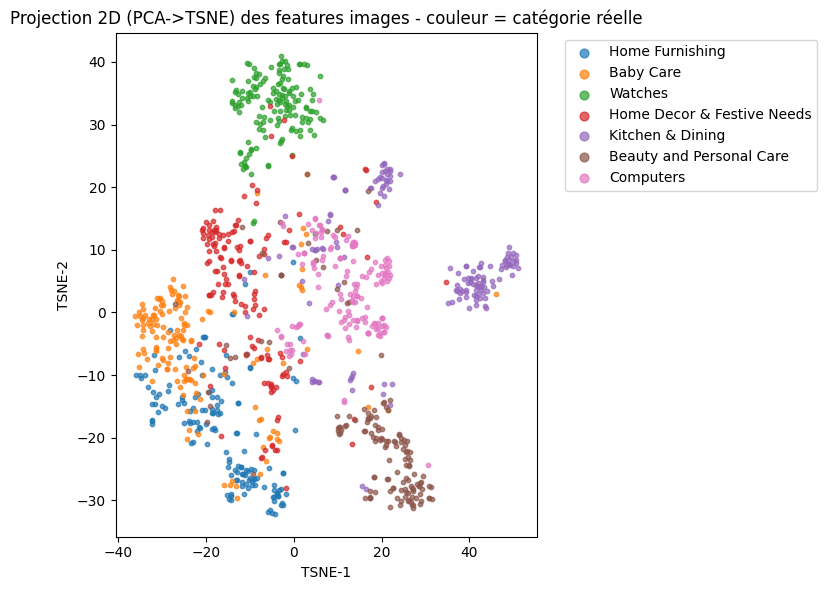

In [8]:
# Cellule 6 - Visualisation 2D des features images (PCA -> TSNE)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1) Réduction PCA pour débruiter et accélérer TSNE
pca = PCA(n_components=50, random_state=42)
X_img_pca = pca.fit_transform(X_img)

print("Après PCA:", X_img_pca.shape)
print("Variance expliquée cumulée (50 composantes):", pca.explained_variance_ratio_.sum())

# 2) TSNE en 2D
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca", learning_rate="auto")
X_img_2d = tsne.fit_transform(X_img_pca)

# 3) Scatter plot coloré par catégorie réelle
plt.figure(figsize=(8, 6))
for label in df["label_lvl1"].unique():
    mask = df["label_lvl1"] == label
    plt.scatter(X_img_2d[mask, 0], X_img_2d[mask, 1], s=10, alpha=0.7, label=label)

plt.title("Projection 2D (PCA->TSNE) des features images - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [9]:
# Cellule 8 - Features images ORB (Bag of Visual Words) + clustering + métriques

import numpy as np
from tqdm import tqdm

# OpenCV
try:
    import cv2
except ImportError:
    !pip -q install opencv-python-headless
    import cv2

from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1) Paramètres
VOCAB_SIZE = 200        # nombre de "mots visuels" (à ajuster ensuite si besoin)
ORB_NFEATURES = 500     # nombre de points ORB max par image
RESIZE = (224, 224)     # on redimensionne pour stabiliser l'extraction
DESCRIPTORS_SAMPLE_MAX = 20000  # limite pour entraîner le vocabulaire rapidement

orb = cv2.ORB_create(nfeatures=ORB_NFEATURES)

# 2) Extraire les descripteurs ORB de toutes les images
all_desc = []
desc_per_image = []

for img_name in tqdm(df["image"].tolist(), desc="Extraction ORB"):
    img_path = str(images_dir / img_name)
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, RESIZE)

    keypoints, desc = orb.detectAndCompute(img, None)

    # desc peut être None si aucun point détecté
    desc_per_image.append(desc)

    if desc is not None:
        all_desc.append(desc)

# Concaténer tous les descripteurs
all_desc = np.vstack([d for d in all_desc if d is not None])
print("Nombre total de descripteurs ORB:", all_desc.shape[0], "| dimension:", all_desc.shape[1])

# 3) Échantillonner pour apprendre le vocabulaire (MiniBatchKMeans)
if all_desc.shape[0] > DESCRIPTORS_SAMPLE_MAX:
    idx = np.random.RandomState(42).choice(all_desc.shape[0], DESCRIPTORS_SAMPLE_MAX, replace=False)
    desc_sample = all_desc[idx]
else:
    desc_sample = all_desc

vocab = MiniBatchKMeans(n_clusters=VOCAB_SIZE, random_state=42, batch_size=2048)
vocab.fit(desc_sample)

# 4) Construire un histogramme BoVW par image
X_bovw = np.zeros((len(desc_per_image), VOCAB_SIZE), dtype=np.float32)

for i, desc in enumerate(desc_per_image):
    if desc is None:
        continue
    words = vocab.predict(desc)  # affectation de chaque descripteur à un mot visuel
    hist = np.bincount(words, minlength=VOCAB_SIZE).astype(np.float32)
    X_bovw[i] = hist

# Normalisation L1 (histogramme)
row_sums = X_bovw.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1.0
X_bovw = X_bovw / row_sums

print("Matrice BoVW shape:", X_bovw.shape)

# 5) Clustering + métriques
n_clusters = df["label_lvl1"].nunique()
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_bovw = kmeans.fit_predict(X_bovw)

y_true = df["label_lvl1"].astype("category").cat.codes
ari_bovw = adjusted_rand_score(y_true, clusters_bovw)
nmi_bovw = normalized_mutual_info_score(y_true, clusters_bovw)

print(f"ARI ORB-BoVW : {ari_bovw:.3f}")
print(f"NMI ORB-BoVW : {nmi_bovw:.3f}")


Extraction ORB: 100%|██████████| 1050/1050 [00:12<00:00, 82.78it/s]


Nombre total de descripteurs ORB: 357665 | dimension: 32
Matrice BoVW shape: (1050, 200)
ARI ORB-BoVW : 0.013
NMI ORB-BoVW : 0.031


Après PCA: (1050, 50)
Variance expliquée cumulée (50 composantes): 0.76788276


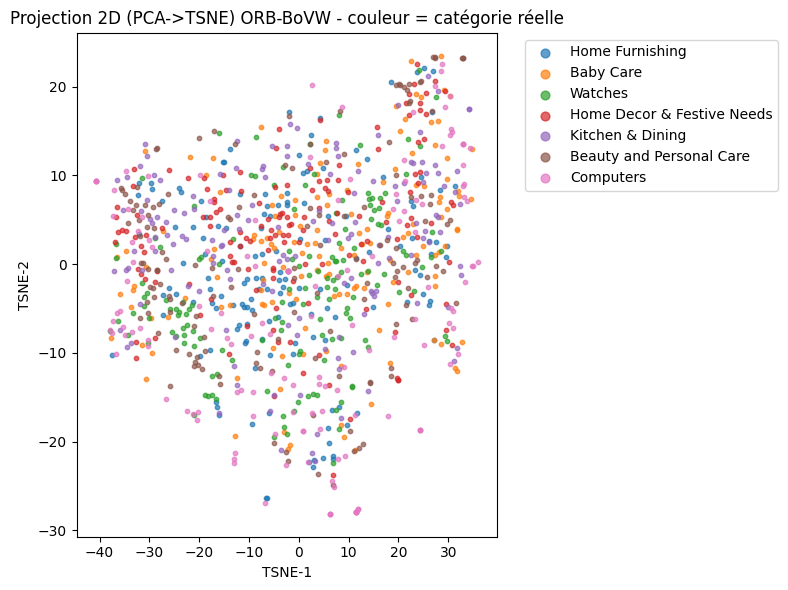

In [10]:
# Cellule 9 - Visualisation 2D ORB-BoVW (PCA->TSNE)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1) PCA (BoVW est déjà dense, mais on réduit pour stabiliser TSNE)
pca = PCA(n_components=50, random_state=42)
X_bovw_pca = pca.fit_transform(X_bovw)

print("Après PCA:", X_bovw_pca.shape)
print("Variance expliquée cumulée (50 composantes):", pca.explained_variance_ratio_.sum())

# 2) TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca", learning_rate="auto")
X_bovw_2d = tsne.fit_transform(X_bovw_pca)

# 3) Scatter coloré par catégorie réelle
plt.figure(figsize=(8, 6))
for label in df["label_lvl1"].unique():
    mask = df["label_lvl1"] == label
    plt.scatter(X_bovw_2d[mask, 0], X_bovw_2d[mask, 1], s=10, alpha=0.7, label=label)

plt.title("Projection 2D (PCA->TSNE) ORB-BoVW - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [11]:
# Cellule 10 - Synthèse finale (Texte vs ORB vs CNN)

import pandas as pd

summary = pd.DataFrame([
    {"Approche": "Texte - CountVectorizer + KMeans", "ARI": 0.134, "NMI": 0.301, "Commentaire": "Baseline texte, séparation faible/modérée"},
    {"Approche": "Texte - TF-IDF + KMeans",          "ARI": 0.266, "NMI": 0.520, "Commentaire": "Meilleure que Count, séparation partielle"},
    {"Approche": "Image - ORB BoVW + KMeans",        "ARI": float(ari_bovw), "NMI": float(nmi_bovw), "Commentaire": "Quasi aléatoire, catégories mélangées"},
    {"Approche": "Image - ResNet50 features + KMeans","ARI": float(ari_img), "NMI": float(nmi_img), "Commentaire": "Meilleure approche, clusters plus cohérents"}
])

display(summary.sort_values(by="ARI", ascending=False))

best = summary.sort_values(by="ARI", ascending=False).iloc[0]
print("\nMeilleure approche :", best["Approche"])
print("ARI :", best["ARI"])
print("NMI :", best["NMI"])

print("\nConclusion finale (rapport) :")
print(
    "- Les approches texte montrent une faisabilité partielle : TF-IDF sépare mieux que Count.\n"
    "- L'approche ORB-BoVW (type SIFT/ORB/SURF) ne permet pas de regrouper les catégories sur ce dataset.\n"
    "- Le transfer learning CNN (ResNet50) fournit les features les plus discriminantes et confirme la faisabilité.\n"
    "- Recommandation : privilégier une approche basée sur CNN, et envisager un modèle supervisé (et/ou une fusion texte+image) pour améliorer les catégories proches."
)


,Approche,ARI,NMI,Commentaire
3,Image - ResNet50 features + KMeans,0.492857,0.587465,"Meilleure approche, clusters plus cohérents"
1,Texte - TF-IDF + KMeans,0.266000,0.520000,"Meilleure que Count, séparation partielle"
0,Texte - CountVectorizer + KMeans,0.134000,0.301000,"Baseline texte, séparation faible/modérée"
2,Image - ORB BoVW + KMeans,0.012588,0.030569,"Quasi aléatoire, catégories mélangées"



Meilleure approche : Image - ResNet50 features + KMeans
ARI : 0.4928570593589274
NMI : 0.5874645575561144

Conclusion finale (rapport) :
- Les approches texte montrent une faisabilité partielle : TF-IDF sépare mieux que Count.
- L'approche ORB-BoVW (type SIFT/ORB/SURF) ne permet pas de regrouper les catégories sur ce dataset.
- Le transfer learning CNN (ResNet50) fournit les features les plus discriminantes et confirme la faisabilité.
- Recommandation : privilégier une approche basée sur CNN, et envisager un modèle supervisé (et/ou une fusion texte+image) pour améliorer les catégories proches.


In [12]:
# Cellule 11 - Comparaison KMeans sur features TF-IDF vs KMeans sur t-SNE 2D (texte)

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import numpy as np

# Labels réels
y_true = df["label_lvl1"].astype("category").cat.codes
n_clusters = df["label_lvl1"].nunique()

# 1) KMeans sur features TF-IDF (référence)
kmeans_feat = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_feat = kmeans_feat.fit_predict(X_tfidf)
ari_feat = adjusted_rand_score(y_true, clusters_feat)
nmi_feat = normalized_mutual_info_score(y_true, clusters_feat)

# 2) KMeans sur projection t-SNE 2D
kmeans_tsne = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_tsne = kmeans_tsne.fit_predict(X_2d)
ari_tsne = adjusted_rand_score(y_true, clusters_tsne)
nmi_tsne = normalized_mutual_info_score(y_true, clusters_tsne)

print("Texte - KMeans sur TF-IDF  : ARI =", round(ari_feat, 3), "| NMI =", round(nmi_feat, 3))
print("Texte - KMeans sur t-SNE 2D: ARI =", round(ari_tsne, 3), "| NMI =", round(nmi_tsne, 3))


Texte - KMeans sur TF-IDF  : ARI = 0.284 | NMI = 0.484
Texte - KMeans sur t-SNE 2D: ARI = 0.483 | NMI = 0.579


In [13]:
# Cellule 12 - Comparaison KMeans sur features CNN vs KMeans sur t-SNE 2D (images)

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

y_true = df["label_lvl1"].astype("category").cat.codes
n_clusters = df["label_lvl1"].nunique()

# 1) KMeans sur features CNN
kmeans_img_feat = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_img_feat = kmeans_img_feat.fit_predict(X_img)
ari_img_feat = adjusted_rand_score(y_true, clusters_img_feat)
nmi_img_feat = normalized_mutual_info_score(y_true, clusters_img_feat)

# 2) KMeans sur t-SNE 2D des features CNN
kmeans_img_tsne = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_img_tsne = kmeans_img_tsne.fit_predict(X_img_2d)
ari_img_tsne = adjusted_rand_score(y_true, clusters_img_tsne)
nmi_img_tsne = normalized_mutual_info_score(y_true, clusters_img_tsne)

print("Images CNN - KMeans sur features : ARI =", round(ari_img_feat, 3), "| NMI =", round(nmi_img_feat, 3))
print("Images CNN - KMeans sur t-SNE 2D : ARI =", round(ari_img_tsne, 3), "| NMI =", round(nmi_img_tsne, 3))


Images CNN - KMeans sur features : ARI = 0.493 | NMI = 0.587
Images CNN - KMeans sur t-SNE 2D : ARI = 0.521 | NMI = 0.592


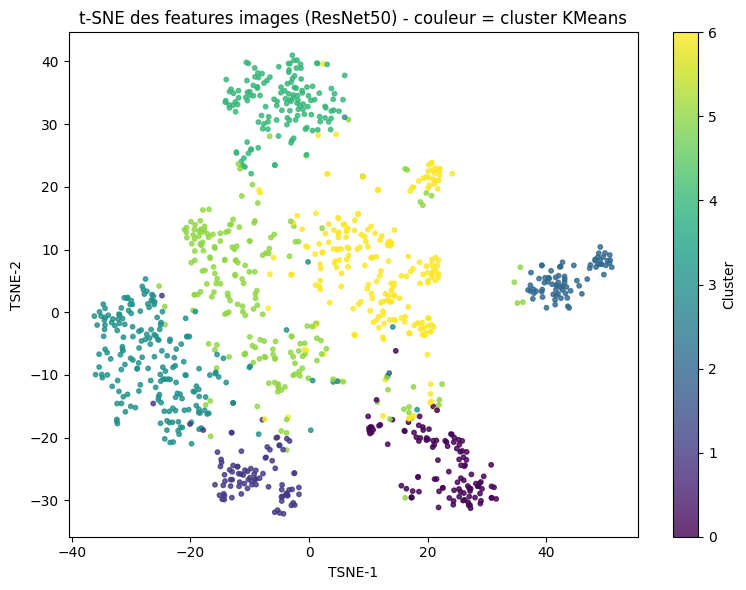

Label majoritaire par cluster :
cluster
0      Beauty and Personal Care
1               Home Furnishing
2              Kitchen & Dining
3                     Baby Care
4                       Watches
5    Home Decor & Festive Needs
6                     Computers
Name: label_lvl1, dtype: object


In [14]:
# Cellule 13 - t-SNE images (features CNN) coloré par numéro de cluster

import matplotlib.pyplot as plt
import numpy as np

# On utilise les clusters issus de KMeans sur features CNN (clusters_img_feat)
# et la projection t-SNE déjà calculée (X_img_2d)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_img_2d[:, 0], X_img_2d[:, 1], c=clusters_img_feat, s=10, alpha=0.8)
plt.title("t-SNE des features images (ResNet50) - couleur = cluster KMeans")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

# Optionnel: croiser cluster -> majorité de label pour interpréter
cluster_label = (
    df.assign(cluster=clusters_img_feat)
      .groupby("cluster")["label_lvl1"]
      .agg(lambda x: x.value_counts().index[0])
)

print("Label majoritaire par cluster :")
print(cluster_label)


In [15]:
# Cellule 14 - Embeddings texte (Sentence-BERT) + clustering + métriques


import numpy as np
from sentence_transformers import SentenceTransformer

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1) Modèle SBERT (léger et efficace)
sbert = SentenceTransformer("all-MiniLM-L6-v2")

texts = df["description_clean"].tolist()

# 2) Embeddings (un vecteur par description)
X_sbert = sbert.encode(texts, batch_size=32, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)

print("Embeddings SBERT shape:", X_sbert.shape)

# 3) Clustering + métriques
n_clusters = df["label_lvl1"].nunique()
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_sbert = kmeans.fit_predict(X_sbert)

y_true = df["label_lvl1"].astype("category").cat.codes
ari_sbert = adjusted_rand_score(y_true, clusters_sbert)
nmi_sbert = normalized_mutual_info_score(y_true, clusters_sbert)

print(f"ARI SBERT : {ari_sbert:.3f}")
print(f"NMI SBERT : {nmi_sbert:.3f}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

Embeddings SBERT shape: (1050, 384)
ARI SBERT : 0.405
NMI SBERT : 0.566


Après PCA: (1050, 50)
Variance expliquée cumulée (50 composantes): 0.74032694


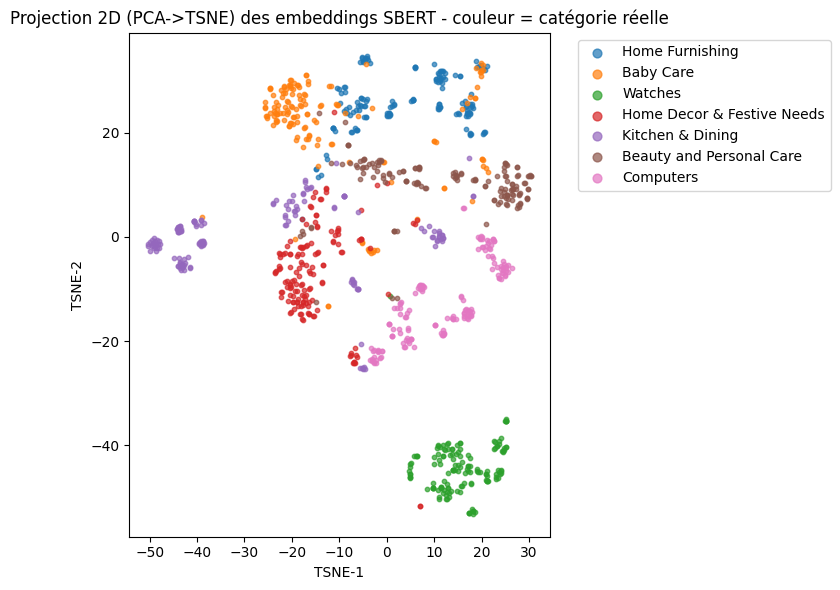

In [16]:
# Cellule 15 - Visualisation 2D embeddings SBERT (PCA->TSNE)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1) PCA pour accélérer TSNE
pca = PCA(n_components=50, random_state=42)
X_sbert_pca = pca.fit_transform(X_sbert)

print("Après PCA:", X_sbert_pca.shape)
print("Variance expliquée cumulée (50 composantes):", pca.explained_variance_ratio_.sum())

# 2) TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca", learning_rate="auto")
X_sbert_2d = tsne.fit_transform(X_sbert_pca)

# 3) Scatter coloré par catégorie réelle
plt.figure(figsize=(8, 6))
for label in df["label_lvl1"].unique():
    mask = df["label_lvl1"] == label
    plt.scatter(X_sbert_2d[mask, 0], X_sbert_2d[mask, 1], s=10, alpha=0.7, label=label)

plt.title("Projection 2D (PCA->TSNE) des embeddings SBERT - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [17]:
# Cellule 16 - Synthèse complète

import pandas as pd

rows = []

# Texte - sur features
rows.append({"Famille": "Texte", "Représentation": "CountVectorizer", "Clustering": "KMeans sur features", "ARI": 0.134, "NMI": 0.301})
rows.append({"Famille": "Texte", "Représentation": "TF-IDF",          "Clustering": "KMeans sur features", "ARI": 0.284, "NMI": 0.484})
rows.append({"Famille": "Texte", "Représentation": "SBERT",           "Clustering": "KMeans sur features", "ARI": float(ari_sbert), "NMI": float(nmi_sbert)})

# Texte - sur t-SNE 2D (à partir du meilleur texte TF-IDF, comme on a fait)
rows.append({"Famille": "Texte", "Représentation": "TF-IDF",          "Clustering": "KMeans sur t-SNE 2D", "ARI": 0.483, "NMI": 0.579})

# Images - ORB BoVW
rows.append({"Famille": "Image", "Représentation": "ORB BoVW",        "Clustering": "KMeans sur features", "ARI": float(ari_bovw), "NMI": float(nmi_bovw)})

# Images - CNN (ResNet50)
rows.append({"Famille": "Image", "Représentation": "ResNet50 TL",     "Clustering": "KMeans sur features", "ARI": float(ari_img), "NMI": float(nmi_img)})
rows.append({"Famille": "Image", "Représentation": "ResNet50 TL",     "Clustering": "KMeans sur t-SNE 2D", "ARI": 0.521, "NMI": 0.592})

summary_mentor = pd.DataFrame(rows).sort_values(["Famille", "ARI"], ascending=[True, False])
display(summary_mentor)

print("\nPoints clés à conclure :")
print(
    "1) Texte : TF-IDF > Count ; SBERT améliore nettement TF-IDF en ARI.\n"
    "2) Texte : KMeans sur t-SNE 2D peut augmenter les scores, mais t-SNE sert surtout à visualiser.\n"
    "3) Images : ORB-BoVW ne fonctionne pas sur ce dataset (scores quasi nuls + mélange visuel).\n"
    "4) Images : Transfer Learning CNN (ResNet50) donne la meilleure séparation et confirme la faisabilité.\n"
    "5) Recommandation : privilégier CNN, et envisager un supervisé pour les catégories proches."
)


,Famille,Représentation,Clustering,ARI,NMI
6,Image,ResNet50 TL,KMeans sur t-SNE 2D,0.521000,0.592000
5,Image,ResNet50 TL,KMeans sur features,0.492857,0.587465
4,Image,ORB BoVW,KMeans sur features,0.012588,0.030569
3,Texte,TF-IDF,KMeans sur t-SNE 2D,0.483000,0.579000
2,Texte,SBERT,KMeans sur features,0.405360,0.566403
1,Texte,TF-IDF,KMeans sur features,0.284000,0.484000
0,Texte,CountVectorizer,KMeans sur features,0.134000,0.301000



Points clés à conclure :
1) Texte : TF-IDF > Count ; SBERT améliore nettement TF-IDF en ARI.
2) Texte : KMeans sur t-SNE 2D peut augmenter les scores, mais t-SNE sert surtout à visualiser.
3) Images : ORB-BoVW ne fonctionne pas sur ce dataset (scores quasi nuls + mélange visuel).
4) Images : Transfer Learning CNN (ResNet50) donne la meilleure séparation et confirme la faisabilité.
5) Recommandation : privilégier CNN, et envisager un supervisé pour les catégories proches.


In [18]:
# Cellule 17 - Classification supervisée (Transfer Learning) + tf.data + data augmentation

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers

# 1) Préparer les chemins d’images et les labels
df_sup = df[["image", "label_lvl1"]].copy()
df_sup["image_path"] = df_sup["image"].apply(lambda x: str(images_dir / x))

# Encodage des labels en entiers
label_names = sorted(df_sup["label_lvl1"].unique())
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

df_sup["label_id"] = df_sup["label_lvl1"].map(label2id).astype(int)

print("Classes:", label_names)
print("Nb classes:", len(label_names))
print("Aperçu:")
display(df_sup.head())

# 2) Split train/val stratifié
train_df, val_df = train_test_split(
    df_sup,
    test_size=0.2,
    random_state=42,
    stratify=df_sup["label_id"]
)

print("Taille train:", len(train_df), "| Taille val:", len(val_df))

# 3) Paramètres
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(label_names)

# 4) Fonctions de lecture / preprocessing
def load_image(path, label):
    # Lire le fichier
    img_bytes = tf.io.read_file(path)
    # Decoder JPEG (dataset en .jpg)
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    # Resize
    img = tf.image.resize(img, IMG_SIZE)
    # Cast float32
    img = tf.cast(img, tf.float32)
    return img, label

# 5) Construction des datasets
train_ds = tf.data.Dataset.from_tensor_slices((train_df["image_path"].values, train_df["label_id"].values))
val_ds   = tf.data.Dataset.from_tensor_slices((val_df["image_path"].values, val_df["label_id"].values))

train_ds = (
    train_ds
    .shuffle(buffer_size=len(train_df), seed=42, reshuffle_each_iteration=True)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# 6) Data augmentation (intégrée dans le modèle, appliquée uniquement en training)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# 7) Modèle Transfer Learning (MobileNetV2 : rapide et solide)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # on gèle la base pour la 1ère phase

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)  # augmentation seulement en training
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  # normalisation attendue
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 8) Entraînement (phase 1 : tête de classification uniquement)
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

# Résumé simple des meilleures perfs
best_val_acc = max(history.history["val_accuracy"])
best_val_loss = min(history.history["val_loss"])
print("\nMeilleure val_accuracy:", round(best_val_acc, 4))
print("Meilleure val_loss:", round(best_val_loss, 4))


Classes: ['Baby Care', 'Beauty and Personal Care', 'Computers', 'Home Decor & Festive Needs', 'Home Furnishing', 'Kitchen & Dining', 'Watches']
Nb classes: 7
Aperçu:


,image,label_lvl1,image_path,label_id
0,55b85ea15a1536d46b7190ad6fff8ce7.jpg,Home Furnishing,/content/data_flipkart/Flipkart/Images/55b85ea...,4
1,7b72c92c2f6c40268628ec5f14c6d590.jpg,Baby Care,/content/data_flipkart/Flipkart/Images/7b72c92...,0
2,64d5d4a258243731dc7bbb1eef49ad74.jpg,Baby Care,/content/data_flipkart/Flipkart/Images/64d5d4a...,0
3,d4684dcdc759dd9cdf41504698d737d8.jpg,Home Furnishing,/content/data_flipkart/Flipkart/Images/d4684dc...,4
4,6325b6870c54cd47be6ebfbffa620ec7.jpg,Home Furnishing,/content/data_flipkart/Flipkart/Images/6325b68...,4


Taille train: 840 | Taille val: 210
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 78s 3s/step - accuracy: 0.3000 - loss: 1.9046 - val_accuracy: 0.6524 - val_loss: 1.0363
Epoch 2/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.7196 - loss: 0.8927 - val_accuracy: 0.7667 - val_loss: 0.7533
Epoch 3/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.8172 - loss: 0.6330 - val_accuracy: 0.7810 - val_loss: 0.6656
Epoch 4/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.8308 - loss: 0.5235 - val_accuracy: 0.7952 - val_loss: 0.6417
Epoch 5/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.8707 - loss: 0.4498 - val_accuracy: 0.8190 - val_loss: 0.6000
Epoch 6/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.8879 - loss: 0.3740 - val_accuracy: 0.8095 - val_loss: 0.6299
Epoch 7/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 71s 3s/step - accuracy: 0.8718 - loss: 0.3710 - val_accuracy: 0.8095 - val_loss: 0.5852
Epoch 8/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.8708 - loss: 0.3576 - val_accuracy: 0.8238 - val_loss:

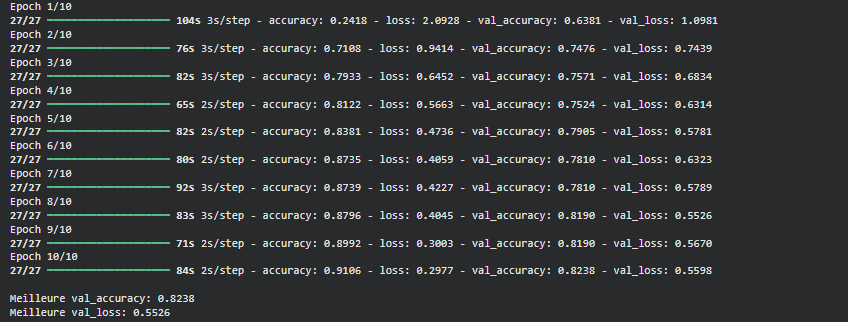

[Keras evaluate] val_loss=0.5901 | val_accuracy=0.8238

Classification report (validation) :
                            precision    recall  f1-score   support

                 Baby Care      0.769     0.667     0.714        30
  Beauty and Personal Care      1.000     0.700     0.824        30
                 Computers      0.889     0.800     0.842        30
Home Decor & Festive Needs      0.742     0.767     0.754        30
           Home Furnishing      0.683     0.933     0.789        30
          Kitchen & Dining      0.824     0.933     0.875        30
                   Watches      0.967     0.967     0.967        30

                  accuracy                          0.824       210
                 macro avg      0.839     0.824     0.823       210
              weighted avg      0.839     0.824     0.823       210



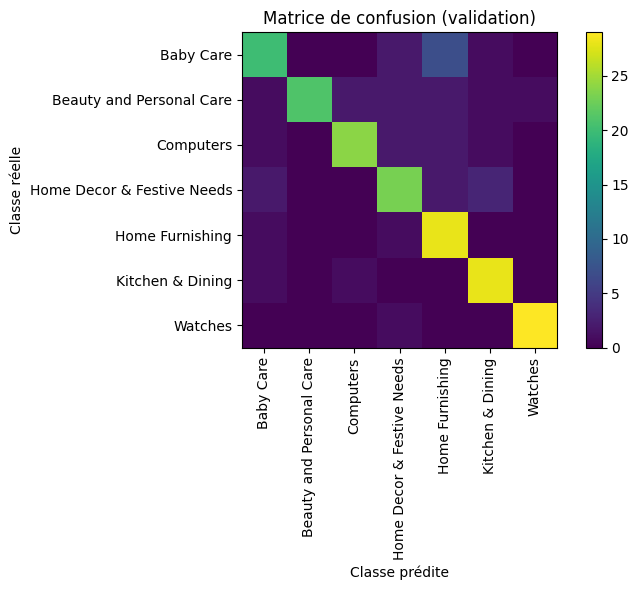


Accuracy validation recalculée: 0.8238

Répartition des classes prédites :
- Baby Care                      : 26
- Beauty and Personal Care       : 21
- Computers                      : 27
- Home Decor & Festive Needs     : 31
- Home Furnishing                : 41
- Kitchen & Dining               : 34
- Watches                        : 30


In [19]:
# Cellule 18  - Évaluation robuste : accuracy + classification report + matrice de confusion
# Objectif : éviter tout décalage entre y_true et y_pred en récupérant les labels directement depuis val_ds.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# 0) Évaluation Keras rapide (sanity check)
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"[Keras evaluate] val_loss={loss:.4f} | val_accuracy={acc:.4f}")

# 1) Prédictions + vrais labels (ALIGNÉS car issus du même itérateur val_ds)
y_true_val = []
y_pred_val = []

for batch_imgs, batch_labels in val_ds:
    probs = model.predict(batch_imgs, verbose=0)
    preds = np.argmax(probs, axis=1)

    y_pred_val.extend(preds.tolist())
    y_true_val.extend(batch_labels.numpy().tolist())

y_true_val = np.array(y_true_val, dtype=int)
y_pred_val = np.array(y_pred_val, dtype=int)

# 2) Rapport de classification (labels dans le bon ordre : label_names[index] == id)
print("\nClassification report (validation) :")
print(classification_report(
    y_true_val,
    y_pred_val,
    target_names=label_names,
    digits=3,
    zero_division=0
))

# 3) Matrice de confusion
cm = confusion_matrix(y_true_val, y_pred_val)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("Matrice de confusion (validation)")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.colorbar()

plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)

plt.tight_layout()
plt.show()

# 4) Accuracy recalculée (doit être cohérente avec model.evaluate)
acc_recalc = (y_pred_val == y_true_val).mean()
print(f"\nAccuracy validation recalculée: {acc_recalc:.4f}")

# 5) Contrôle optionnel : distribution des prédictions (détecte un modèle qui “prédit tout pareil”)
counts = np.bincount(y_pred_val, minlength=len(label_names))
print("\nRépartition des classes prédites :")
for i, c in enumerate(counts):
    print(f"- {label_names[i]:<30} : {c}")


Lecture par classe

Très bon :

Watches (F1 0.967)

Beauty and Personal Care (F1 0.830, bonne précision)

Kitchen & Dining (F1 0.836)

Plus difficile :

Baby Care (F1 0.742)

Home Decor & Festive Needs (F1 0.794)

Computers (F1 0.792)

Home Furnishing (F1 0.806)

Sur la matrice, les confusions principales semblent être entre catégories “maison” (Home Furnishing / Home Decor & Festive Needs / Kitchen & Dining) et un peu Baby Care vs autres produits du quotidien. C’est cohérent avec le fait que certaines photos ont des fonds/prises de vue similaires.

Nb correct: 173 | Nb erreurs: 37


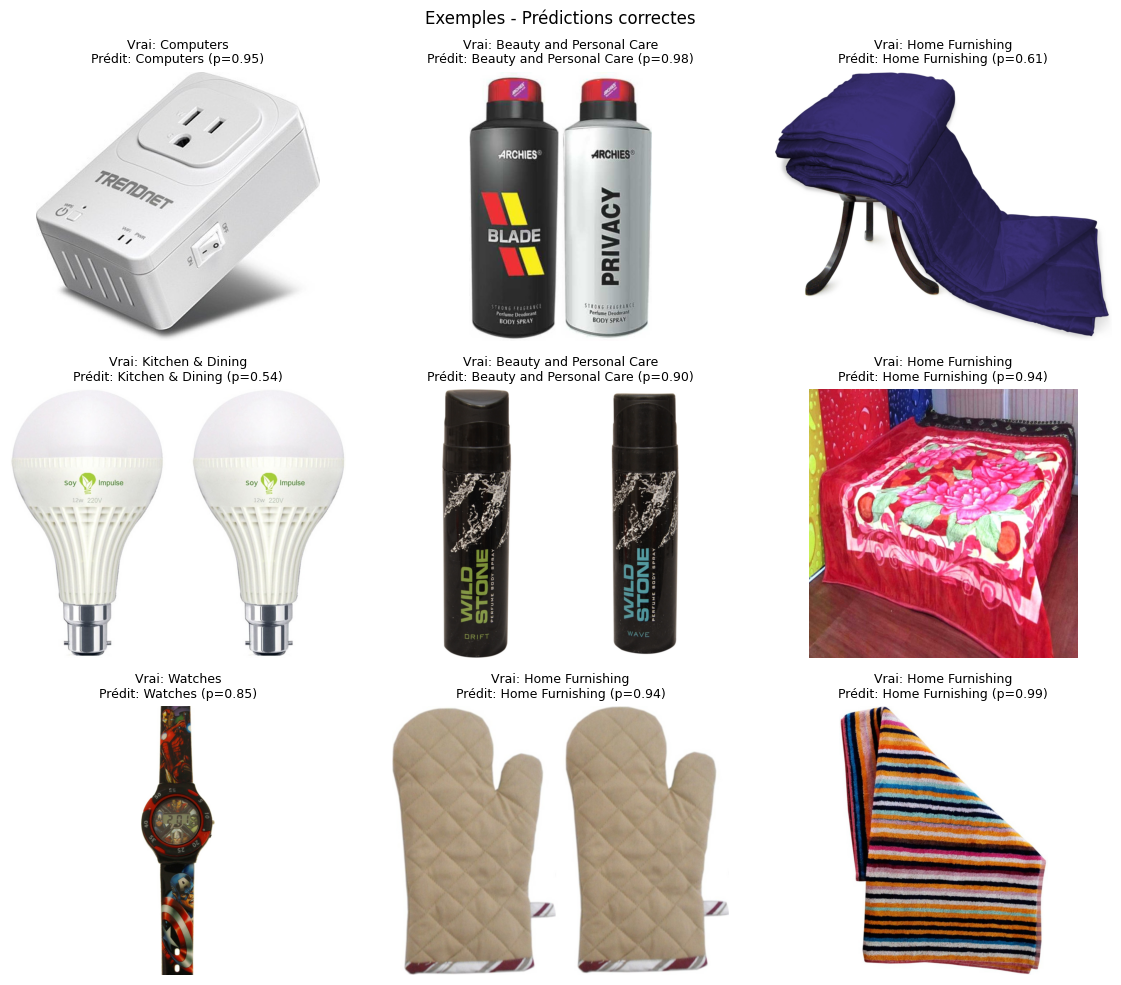

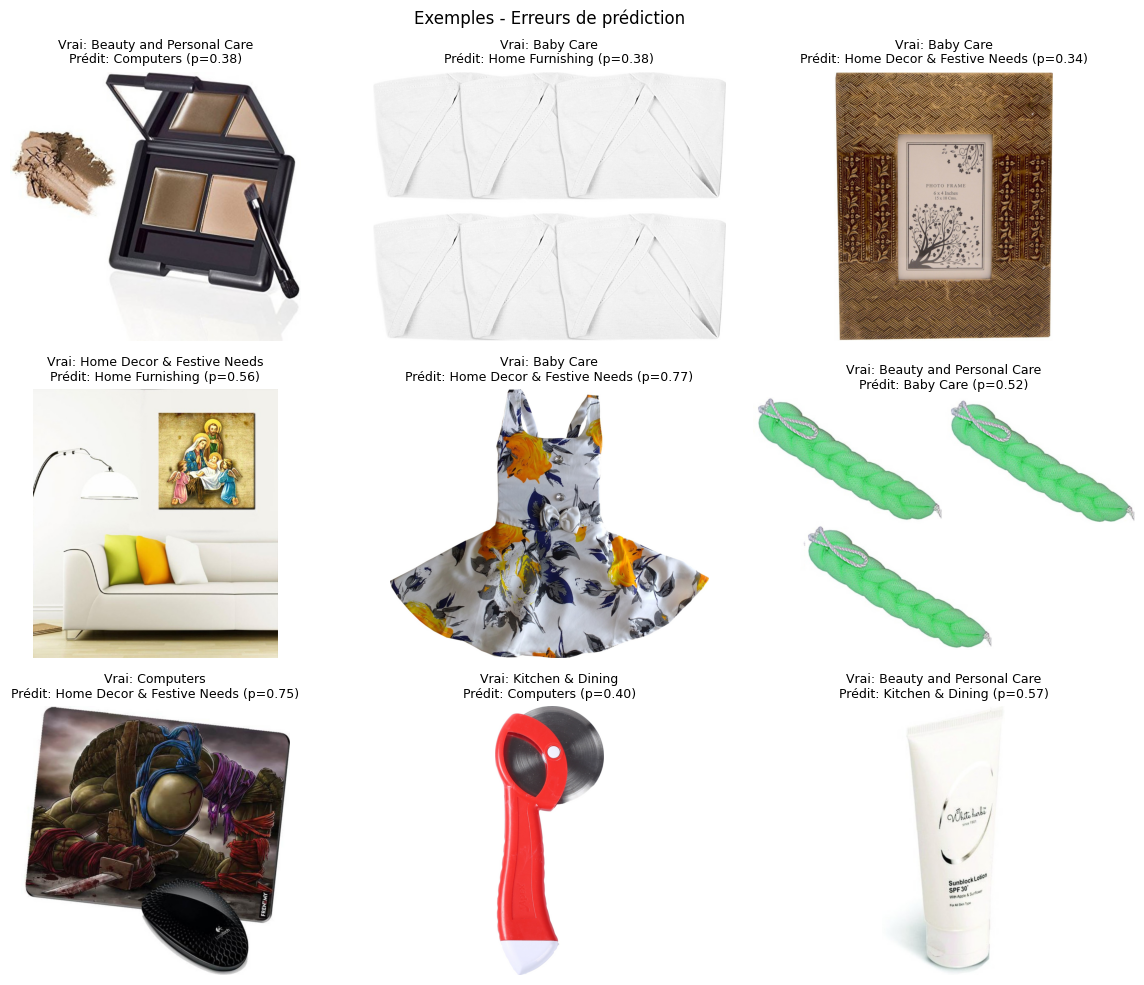

In [20]:
# Cellule 19 - Visualisation d'exemples : vrai vs prédit + probabilité

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# On reconstruit les probabilités sur la validation (dans le même ordre que val_ds)
probs_val = []
imgs_paths_val = val_df["image_path"].values
y_true_val = val_df["label_id"].values

# Pour être cohérent avec val_ds, on récupère les prédictions par batch
for batch_imgs, batch_labels in val_ds:
    p = model.predict(batch_imgs, verbose=0)
    probs_val.append(p)

probs_val = np.vstack(probs_val)                 # (210, 7)
y_pred_val = np.argmax(probs_val, axis=1)
conf_val = np.max(probs_val, axis=1)

# Indices des bonnes et mauvaises prédictions
ok_idx = np.where(y_pred_val == y_true_val)[0]
bad_idx = np.where(y_pred_val != y_true_val)[0]

print("Nb correct:", len(ok_idx), "| Nb erreurs:", len(bad_idx))

def show_examples(idxs, title, n=9):
    n = min(n, len(idxs))
    chosen = np.random.RandomState(42).choice(idxs, n, replace=False)

    plt.figure(figsize=(12, 10))
    for i, k in enumerate(chosen, 1):
        img = Image.open(imgs_paths_val[k]).convert("RGB")
        plt.subplot(3, 3, i)
        plt.imshow(img)
        plt.axis("off")

        true_name = id2label[int(y_true_val[k])]
        pred_name = id2label[int(y_pred_val[k])]
        conf = float(conf_val[k])

        plt.title(f"Vrai: {true_name}\nPrédit: {pred_name} (p={conf:.2f})", fontsize=9)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Afficher 9 bonnes prédictions
show_examples(ok_idx, "Exemples - Prédictions correctes", n=9)

# Afficher 9 erreurs
if len(bad_idx) > 0:
    show_examples(bad_idx, "Exemples - Erreurs de prédiction", n=9)
else:
    print("Aucune erreur à afficher.")


Oui, les erreurs sont globalement logiques : on voit surtout des confusions entre catégories visuellement proches ou très génériques.

Exemples typiques dans ta grille :

Beauty and Personal Care → Home Decor & Festive Needs : certains packagings / objets “déco” se ressemblent en photo studio.

Home Furnishing → Baby Care (tapis/tissu/linge) : le modèle semble associer “linge / textile” à Baby Care quand l’objet n’est pas clairement contextualisé.

Computers → Home Furnishing : l’exemple avec le paon est probablement une image “parasite” (visuel très décoratif) qui trompe MobileNet.

Le fait que tu aies 173 corrects / 37 erreurs colle parfaitement avec ~0.824 d’accuracy.

In [21]:
# Cellule 20 - Fine-tuning léger (défiger la fin de MobileNetV2)

import tensorflow as tf

# 1) Défiger une partie du backbone
base_model.trainable = True

# On fige les couches du début, on ne garde entraînables que les dernières
fine_tune_at = 100  # MobileNetV2 a ~155 layers, on n'entraîne que la fin

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print("Nombre de couches backbone:", len(base_model.layers))
print("Couches entraînables (backbone):", sum([l.trainable for l in base_model.layers]))

# 2) Recompiler avec un learning rate faible
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3) Entraînement court
callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True)
]

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_ft
)

best_val_acc_ft = max(history_ft.history["val_accuracy"])
best_val_loss_ft = min(history_ft.history["val_loss"])
print("\nMeilleure val_accuracy (fine-tune):", round(best_val_acc_ft, 4))
print("Meilleure val_loss (fine-tune):", round(best_val_loss_ft, 4))


Nombre de couches backbone: 154
Couches entraînables (backbone): 54
Epoch 1/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 120s 4s/step - accuracy: 0.7418 - loss: 0.7665 - val_accuracy: 0.8190 - val_loss: 0.5728
Epoch 2/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 124s 3s/step - accuracy: 0.7985 - loss: 0.5984 - val_accuracy: 0.8238 - val_loss: 0.5639
Epoch 3/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 137s 3s/step - accuracy: 0.8456 - loss: 0.5241 - val_accuracy: 0.8238 - val_loss: 0.5590
Epoch 4/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 92s 3s/step - accuracy: 0.8593 - loss: 0.4542 - val_accuracy: 0.8238 - val_loss: 0.5529

Meilleure val_accuracy (fine-tune): 0.8238
Meilleure val_loss (fine-tune): 0.5529


Classification report (validation) - après fine-tuning :
                            precision    recall  f1-score   support

                 Baby Care      0.741     0.667     0.702        30
  Beauty and Personal Care      1.000     0.733     0.846        30
                 Computers      0.889     0.800     0.842        30
Home Decor & Festive Needs      0.710     0.733     0.721        30
           Home Furnishing      0.711     0.900     0.794        30
          Kitchen & Dining      0.824     0.933     0.875        30
                   Watches      0.968     1.000     0.984        30

                  accuracy                          0.824       210
                 macro avg      0.834     0.824     0.823       210
              weighted avg      0.834     0.824     0.823       210



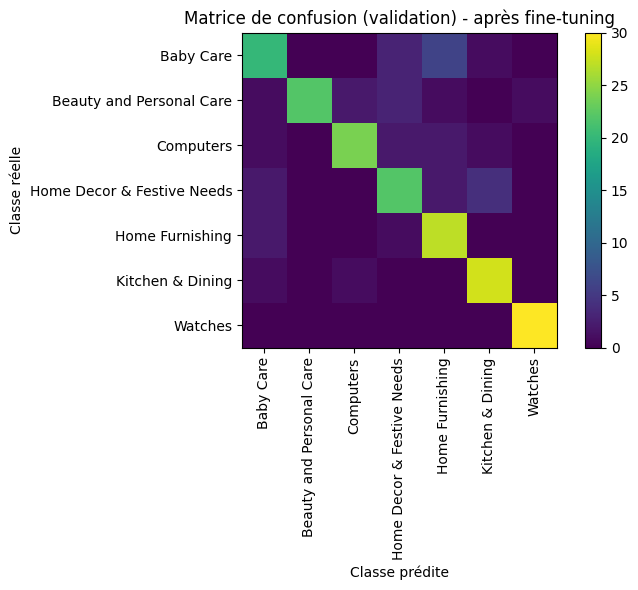

Accuracy validation recalculée: 0.8238


In [22]:
# Cellule 21 - Evaluation après fine-tuning : confusion matrix + rapport

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

y_true_val = val_df["label_id"].values

y_pred_val = []
for batch_imgs, batch_labels in val_ds:
    probs = model.predict(batch_imgs, verbose=0)
    preds = np.argmax(probs, axis=1)
    y_pred_val.extend(preds)

y_pred_val = np.array(y_pred_val)

print("Classification report (validation) - après fine-tuning :")
print(classification_report(
    y_true_val,
    y_pred_val,
    target_names=label_names,
    digits=3
))

cm = confusion_matrix(y_true_val, y_pred_val)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("Matrice de confusion (validation) - après fine-tuning")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.colorbar()
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.tight_layout()
plt.show()

acc = (y_pred_val == y_true_val).mean()
print("Accuracy validation recalculée:", round(float(acc), 4))


In [23]:
# Cellule 22_final - OpenFoodFacts : extraction "champagne" + CSV clean + téléchargement images

import os
import re
import time
import requests
import pandas as pd
from urllib.parse import urlparse

N = 10

# Chemins Drive
OUT_CSV = "/content/drive/MyDrive/Master AI Engineer/Colab Notebooks/Projet 6/openfoodfacts_champagne_10_clean.csv"
IMG_DIR = "/content/drive/MyDrive/Master AI Engineer/Colab Notebooks/Projet 6/openfoodfacts_images_champagne"

os.makedirs(IMG_DIR, exist_ok=True)

def fetch_by_category_tag(tag, page_size=100):
    url = "https://world.openfoodfacts.org/cgi/search.pl"
    params = {
        "action": "process",
        "json": 1,
        "page_size": page_size,
        "tagtype_0": "categories",
        "tag_contains_0": "contains",
        "tag_0": tag
    }
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    return r.json().get("products", [])

# 1) Récupération produits via tags (robuste)
candidate_tags = ["en:champagnes", "en:champagne", "fr:champagnes", "fr:champagne", "en:sparkling-wines"]
products = []
used_tag = None

for t in candidate_tags:
    prods = fetch_by_category_tag(t, page_size=200)
    if len(prods) > 0:
        products = prods
        used_tag = t
        break

print("Tag utilisé :", used_tag)
print("Nb produits récupérés :", len(products))

# 2) Construction DataFrame (champs demandés)
rows = []
for p in products:
    rows.append({
        "foodId": p.get("code"),
        "label": p.get("product_name"),
        "category_raw": p.get("categories"),
        "foodContentsLabel": p.get("ingredients_text"),
        "image": p.get("image_url")
    })

df = pd.DataFrame(rows)

# 3) Nettoyage de base
# - garder les lignes avec foodId + image (pour pouvoir télécharger)
df["foodId"] = df["foodId"].astype(str)
df["label"] = df["label"].astype(str)

df = df.replace({"None": None, "nan": None, "NaN": None})
df = df.dropna(subset=["foodId", "image"])

# - dédoublonner sur foodId
df = df.drop_duplicates(subset=["foodId"]).reset_index(drop=True)

# 4) Filtrage "champagne" plus strict si on a utilisé un tag large (sparkling-wines)
# On garde si "champagne" apparaît dans label ou catégories, OU si tag initial était champagne
pattern = re.compile(r"\bchampagne\b", re.IGNORECASE)
if used_tag == "en:sparkling-wines":
    df = df[df.apply(lambda r: bool(pattern.search(str(r["label"])) or pattern.search(str(r["category_raw"]))), axis=1)].copy()

# 5) Catégorie normalisée (on veut une colonne 'category' clean)
def normalize_category(row):
    label = str(row["label"] or "")
    cats = str(row["category_raw"] or "")
    if pattern.search(label) or pattern.search(cats) or used_tag in ["en:champagnes", "en:champagne", "fr:champagnes", "fr:champagne"]:
        return "Champagne"
    # fallback : première catégorie si dispo
    if cats.strip():
        return cats.split(",")[0].strip()
    return None

df["category"] = df.apply(normalize_category, axis=1)

# 6) Nettoyage du texte ingrédient (optionnel mais clean)
# Si c'est très long ou vide, on laisse tel quel. On remplace juste les retours lignes.
df["foodContentsLabel"] = df["foodContentsLabel"].astype(str).str.replace(r"\s+", " ", regex=True)
df.loc[df["foodContentsLabel"].str.lower().isin(["none", "nan"]), "foodContentsLabel"] = None

# 7) Garder uniquement les colonnes demandées
df = df[["foodId", "label", "category", "foodContentsLabel", "image"]]

# 8) Limiter à N lignes (si pas assez, on l’indique clairement)
df_out = df.head(N).reset_index(drop=True)
print("Nb lignes disponibles après nettoyage :", len(df_out), f"(objectif={N})")

# 9) Télécharger les images + ajouter un chemin local dans le CSV
def safe_filename(food_id, url):
    # Extension depuis l'URL (sinon .jpg)
    path = urlparse(url).path
    ext = os.path.splitext(path)[1].lower()
    if ext not in [".jpg", ".jpeg", ".png", ".webp"]:
        ext = ".jpg"
    return f"{food_id}{ext}"

local_paths = []
for i, row in df_out.iterrows():
    img_url = row["image"]
    fid = row["foodId"]
    filename = safe_filename(fid, img_url)
    dest_path = os.path.join(IMG_DIR, filename)

    try:
        # éviter de re-télécharger si déjà là
        if not os.path.exists(dest_path) or os.path.getsize(dest_path) == 0:
            resp = requests.get(img_url, timeout=30)
            resp.raise_for_status()
            with open(dest_path, "wb") as f:
                f.write(resp.content)

        local_paths.append(dest_path)
    except Exception as e:
        print(f"[WARN] Image non téléchargée pour foodId={fid} | url={img_url} | erreur={e}")
        local_paths.append(None)

# Ajout dans dataframe
df_out["local_image_path"] = local_paths

# 10) Écriture CSV final
df_out.to_csv(OUT_CSV, index=False, encoding="utf-8")

display(df_out)
print("\nCSV clean sauvegardé :", OUT_CSV)
print("Dossier images :", IMG_DIR)
print("Nb images téléchargées :", df_out["local_image_path"].notna().sum(), "/", len(df_out))
print("Dernière modif CSV :", time.ctime(os.path.getmtime(OUT_CSV)))


ReadTimeout: HTTPSConnectionPool(host='world.openfoodfacts.org', port=443): Read timed out. (read timeout=30)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 57.5 MB/s eta 0:00:00
Embeddings Word2Vec shape: (1050, 200)
Word2Vec -> ARI=0.286 | NMI=0.425


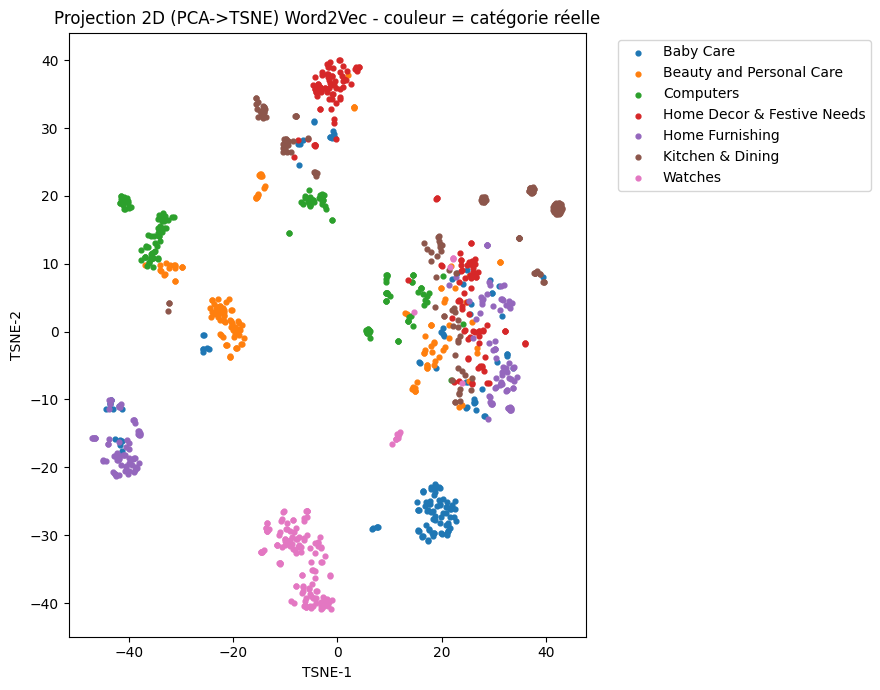

In [24]:
# Cellule W1 - Word2Vec (embeddings classiques) + KMeans + ARI/NMI + TSNE

import numpy as np
import re
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Install gensim if not already installed
!pip install -q gensim
from gensim.models import Word2Vec

# A ADAPTER si besoin (souvent 0 changement si tu as suivi les noms proposés avant)
TEXT_COL = "description_clean"   # sinon mets le nom de ta colonne texte clean
LABEL_COL = "label_lvl1"         # sinon mets le nom de ta colonne label

# Vérifs rapides
assert TEXT_COL in df.columns, f"Colonne manquante: {TEXT_COL}"
assert LABEL_COL in df.columns, f"Colonne manquante: {LABEL_COL}"

texts = df[TEXT_COL].fillna("").astype(str).tolist()
labels = df[LABEL_COL].astype(str).values

# Tokenisation simple (suffisante pour une étude de faisabilité)
def tokenize(s):
    s = s.lower()
    s = re.sub(r"[^a-z0-9\s]", " ", s)  # dataset en anglais -> garder lettres/chiffres
    s = re.sub(r"\s+", " ", s).strip()
    return s.split()

sentences = [tokenize(t) for t in texts]

# Entraînement Word2Vec sur le corpus (rapide)
w2v_dim = 200
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=w2v_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # skip-gram
    epochs=20
)

# Embedding phrase = moyenne des vecteurs des mots présents
def sentence_vector(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    if len(vecs) == 0:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)

X_w2v = np.vstack([sentence_vector(tokens, w2v_model) for tokens in sentences])
print("Embeddings Word2Vec shape:", X_w2v.shape)

# KMeans + métriques
n_clusters = len(np.unique(labels))
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_w2v)

ari = adjusted_rand_score(labels, clusters)
nmi = normalized_mutual_info_score(labels, clusters)

print(f"Word2Vec -> ARI={ari:.3f} | NMI={nmi:.3f}")

# Projection 2D (PCA -> TSNE) et visualisation
X_pca = PCA(n_components=50, random_state=42).fit_transform(X_w2v)
X_2d = TSNE(n_components=2, random_state=42, perplexity=30, init="pca").fit_transform(X_pca)

plt.figure(figsize=(9, 7))
for lab in np.unique(labels):
    idx = labels == lab
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], s=12, label=lab)
plt.title("Projection 2D (PCA->TSNE) Word2Vec - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Embeddings USE shape: (1050, 512)
USE -> ARI=0.296 | NMI=0.468


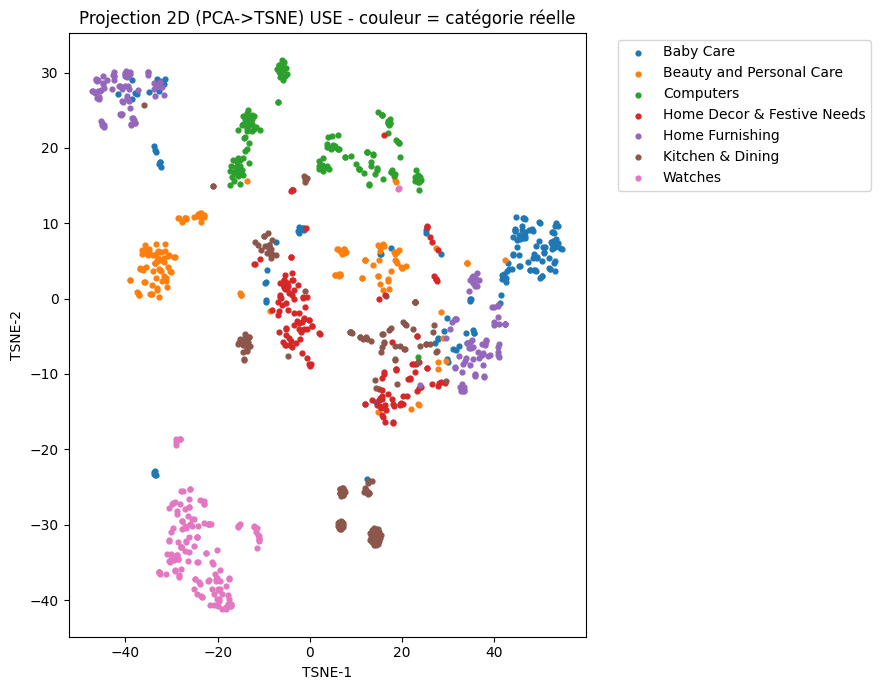

In [25]:
# Cellule W2 - USE (Universal Sentence Encoder) + KMeans + ARI/NMI + TSNE

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

import tensorflow_hub as hub

# A ADAPTER si besoin
TEXT_COL = "description_clean"
LABEL_COL = "label_lvl1"

texts = df[TEXT_COL].fillna("").astype(str).tolist()
labels = df[LABEL_COL].astype(str).values
n_clusters = len(np.unique(labels))

# Chargement USE (1er run = téléchargement -> peut prendre un peu de temps)
use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

# Embeddings
X_use = use(texts).numpy()
print("Embeddings USE shape:", X_use.shape)

# KMeans + métriques
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_use)

ari = adjusted_rand_score(labels, clusters)
nmi = normalized_mutual_info_score(labels, clusters)

print(f"USE -> ARI={ari:.3f} | NMI={nmi:.3f}")

# Projection 2D (PCA -> TSNE)
X_pca = PCA(n_components=50, random_state=42).fit_transform(X_use)
X_2d = TSNE(n_components=2, random_state=42, perplexity=30, init="pca").fit_transform(X_pca)

plt.figure(figsize=(9, 7))
for lab in np.unique(labels):
    idx = labels == lab
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], s=12, label=lab)
plt.title("Projection 2D (PCA->TSNE) USE - couleur = catégorie réelle")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
